# C-β-VAE conjunto — regresión + reconstrucción auxiliar + data augmentation

Encoder compartido entre una rama VAE (reparam + KL, decoder sigmoide + BCE)
y una cabeza de regresión de GY (loss Pearson). Pérdida total

$$L = \mathrm{pearson}(\hat y, y) + \lambda\,(\mathrm{BCE}(\text{decoder}, X) + \beta\,\mathrm{KL}).$$

Este notebook tiene cuatro partes:

1. Entrenamiento del C-β-VAE (train 2017+2018 -> val 2019; 2020 sellado).
2. Calidad de generación: cómo son los datos sintéticos (reconstrucción, frecuencias alélicas, distribución de GY).
3. El modelo por sí solo: el C-β-VAE como regresor, con IC95% por bootstrap, contra GBLUP y MLP.
4. Data augmentation: reentrenar un modelo downstream con train real + sintéticos y compararlo contra el original.

> Reglas respetadas: el VAE y los sintéticos se derivan solo del train; el val es 100 % real;
> las filas sintéticas reciben `line_id` centinela que nunca cruza a val; la entrada queda binaria
> para la BCE.

## 0 * Setup

In [1]:
import os, sys, pathlib, copy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = pathlib.Path.cwd()
while not (ROOT / "src").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
os.chdir(ROOT)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
os.environ.setdefault("WANDB_MODE", "offline")

from src.utils.config import load_config, set_nested
from src.utils.seed import set_seed
from src.data.loader import load_dataset
from src.eval.splits import fixed_temporal_split
from src.models.registry import build_model
from src.eval import augment as aug
from src.eval.nb_eval import make_evaluators
from src.eval.report_plots import plot_ci, plot_box, plot_paired_diff, plot_allele_freq, plot_dist_overlay

CBETA_BASE  = "configs/exp_cbeta_vae_2017_to_2018.yaml"
CBETA_SWEEP = "oromagnoli-/maze-genomic-pred/clj5gbf2"
print("ROOT:", ROOT)

ROOT: c:\Users\MODDE\Desktop\Udesa\ML\PF\maze-genomic-pred


## 1 * Entrenar el C-β-VAE

Cargamos el config base y, si hay un sweep, le aplicamos los HP ganadores (selección honesta en 2018).
Después entrenamos solo con el train real 2017+2018 (val 2019 queda intocado para el reporte).

In [2]:
cfg = load_config(CBETA_BASE)
if CBETA_SWEEP:
    try:
        from src.training.sweep import best_run_from_sweep
        ov, val2018, rid = best_run_from_sweep(CBETA_SWEEP)
        for k, v in ov.items():
            set_nested(cfg, k, v)
        print(f"HP del sweep (run {rid}, pearson_r val2018={val2018:.4f})")
    except Exception as e:
        print(f"[warn] sin sweep usable ({e}); uso config base")
else:
    print("[info] CBETA_SWEEP=None -> uso los HP base del YAML")

set_seed(int(cfg.get("seed", 575)))

ds  = load_dataset(cfg["data"]["geno_csv"], cfg["data"]["pheno_csv"])
arr = ds.to_modeling_arrays(target=cfg["data"]["target"], env=cfg["data"]["env"])
(tr, va) = fixed_temporal_split(arr.year, arr.line_id, val_year=2019,
                                train_years=[2017, 2018], holdout_test_year=2020)[0]
Xtr, ytr   = arr.X[tr], arr.y[tr]
Xva, ytrue = arr.X[va], arr.y[va]
line_tr, year_tr = arr.line_id[tr], arr.year[tr]
line_va = arr.line_id[va]
print(f"train n={len(tr)}  val n={len(va)}  p={Xtr.shape[1]}  binaria={set(np.unique(Xtr[:50]).tolist())}")

model = build_model(cfg)
model.set_fit_context(year=year_tr, line_id=line_tr)
model.fit(Xtr, ytr)
fp = model.get_fitted_params()
print("C-β-VAE entrenado.")
print(f"  pearson(val 2019) = {np.corrcoef(model.predict(Xva), ytrue)[0,1]:.4f}")
print(f"  latent_dim={fp['latent_dim']}  KL final={fp.get('kl_final'):.4f}  BCE final={fp.get('bce_final'):.4f}  n_params={fp['n_params']:,}")

wandb: [wandb.Api()] Loaded credentials for https://api.wandb.ai from C:\Users\MODDE\.netrc.


HP del sweep (run k73isx7m, pearson_r val2018=0.4176)
train n=2319  val n=722  p=4612  binaria={0, 1}
C-β-VAE entrenado.
  pearson(val 2019) = 0.2659
  latent_dim=32  KL final=2.3925  BCE final=0.6899  n_params=21,070,021


## 2 * Calidad de la generación

¿Cómo son los datos generados? Comparamos las dos estrategias:

- posterior-jitter (conserva el label real): encodea líneas reales, perturba el latente, decodea SNPs cercanos al manifold.
- prior-sampling (label de la reg-head): muestrea `z~N(0,I)` y decodea genotipos novedosos.

Miramos: accuracy de reconstrucción, frecuencia alélica por SNP real vs sintética (la generación debería respetar
las frecuencias marginales), la distribución de GY, y cuántas dimensiones latentes quedaron activas (colapso posterior).

In [3]:
rep_post  = aug.generation_report(model, Xtr, strategy="posterior", n=len(Xtr), y_real=ytr, seed=575)
rep_prior = aug.generation_report(model, Xtr, strategy="prior",     n=len(Xtr), y_real=ytr, seed=575)

print(f"reconstrucción (acc bit a bit) sobre el train: {rep_post['recon_acc']:.3f}")
print(f"dims latentes activas: {rep_post['active_dims']} / {model.cfg_['latent_dim']}  (≈0 ⇒ colapso posterior)")
print(f"MAF corr real↔sintética:  posterior={rep_post['maf_corr']:.3f}   prior={rep_prior['maf_corr']:.3f}")
print("ejemplo de 1 genotipo sintético (primeros 30 SNPs):")
print(" ", rep_prior["X_synth"][0, :30].astype(int))

reconstrucción (acc bit a bit) sobre el train: 0.680
dims latentes activas: 7 / 32  (≈0 ⇒ colapso posterior)
MAF corr real↔sintética:  posterior=0.277   prior=0.248
ejemplo de 1 genotipo sintético (primeros 30 SNPs):
  [1 0 0 1 0 0 1 1 1 0 1 1 1 0 1 1 1 1 0 1 1 1 0 0 1 0 0 0 1 0]


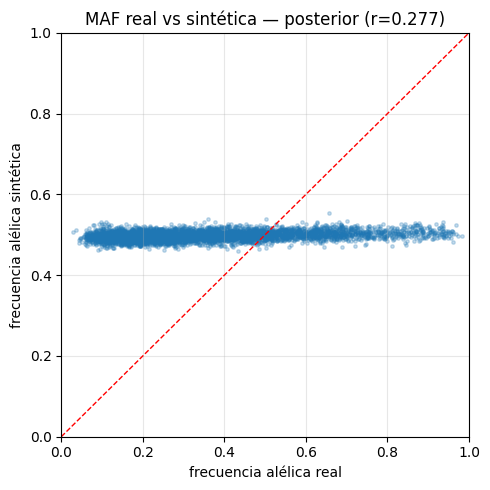

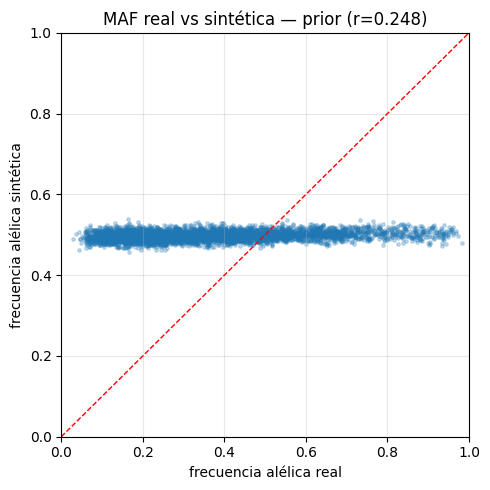

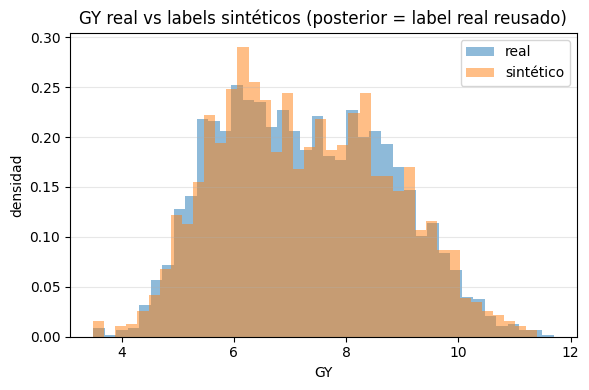

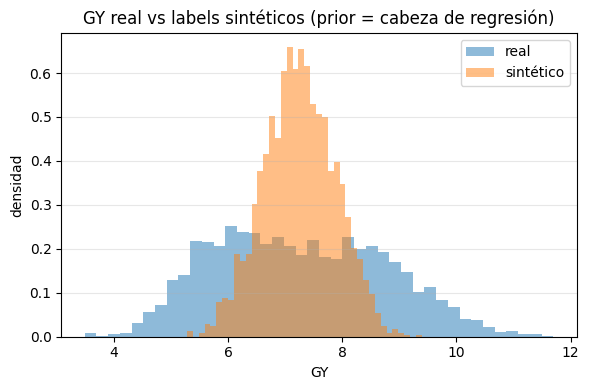

In [4]:
fig = plot_allele_freq(rep_post["maf_real"], rep_post["maf_synth"],
                       title=f"MAF real vs sintética — posterior (r={rep_post['maf_corr']:.3f})")
plt.show()
fig = plot_allele_freq(rep_prior["maf_real"], rep_prior["maf_synth"],
                       title=f"MAF real vs sintética — prior (r={rep_prior['maf_corr']:.3f})")
plt.show()

fig = plot_dist_overlay(rep_post["y_real"], rep_post["y_synth"], label="GY",
                        title="GY real vs labels sintéticos (posterior = label real reusado)")
plt.show()
fig = plot_dist_overlay(rep_prior["y_real"], rep_prior["y_synth"], label="GY",
                        title="GY real vs labels sintéticos (prior = cabeza de regresión)")
plt.show()

## 3 * El modelo por sí solo (regresor)

El C-β-VAE como predictor de GY, evaluado en val 2019 con IC95% por bootstrap (cluster por línea),
contra los baselines GBLUP y MLP. Reusa `make_evaluators` (corre `run_evaluation`, cachea en disco,
no toca wandb). Nota: con loss Pearson la salida queda sin calibrar en escala => RMSE/R² no son
informativos; la portada es `pearson_r` (y `matching20` para selección).

In [5]:
METRICS = ("pearson_r", "rmse", "r2", "matching20")
evaluate_model, _, curves, _ = make_evaluators(METRICS, n_boot=2000, alpha=0.05)

REPORT_CV = {"scheme": "fixed_temporal", "val_year": 2019, "train_years": [2017, 2018],
             "holdout_test_year": 2020, "enforce_disjoint_lines": True}

def with_report_cv(base_path):
    c = load_config(base_path)
    c["cv"] = dict(REPORT_CV)
    c["artifacts"] = {"save_model": False}
    return c

cfg_cbeta = copy.deepcopy(cfg)
cfg_cbeta["cv"] = dict(REPORT_CV)
cfg_cbeta["artifacts"] = {"save_model": False}

CONFIGS = {
    "C-β-VAE":      cfg_cbeta,
    "GBLUP (REML)": with_report_cv("configs/exp_gblup_2017_to_2018.yaml"),
    "MLP (Pearson)": with_report_cv("configs/exp_mlp_2017_to_2018.yaml"),
}

rows, samples_by_model = [], {}
for name, c in CONFIGS.items():
    r, s = evaluate_model(name, c)
    rows += r
    samples_by_model[name] = s
    print(f"[ok] {name}")

df = pd.DataFrame(rows)
print(df.pivot(index="model", columns="metric", values="point").round(4))

  [cache hit] C-β-VAE (d718e66721d7f554)
[ok] C-β-VAE
  [cache hit] GBLUP (REML) (90f1d6fe13802d36)
[ok] GBLUP (REML)
  [cache hit] MLP (Pearson) (bba1687963621c86)
[ok] MLP (Pearson)
metric         matching20  pearson_r       r2    rmse
model                                                
C-β-VAE            0.3472     0.2659  -0.4471  1.2137
GBLUP (REML)       0.3958     0.3145  -0.6644  1.3016
MLP (Pearson)      0.2708     0.2092 -14.7642  4.0059


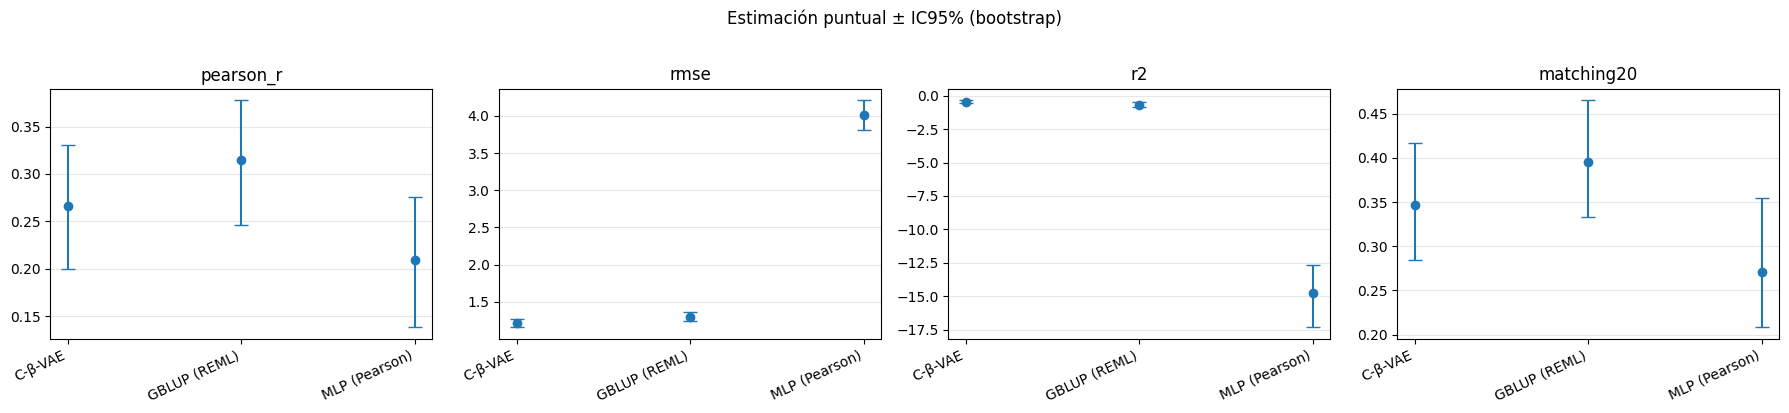

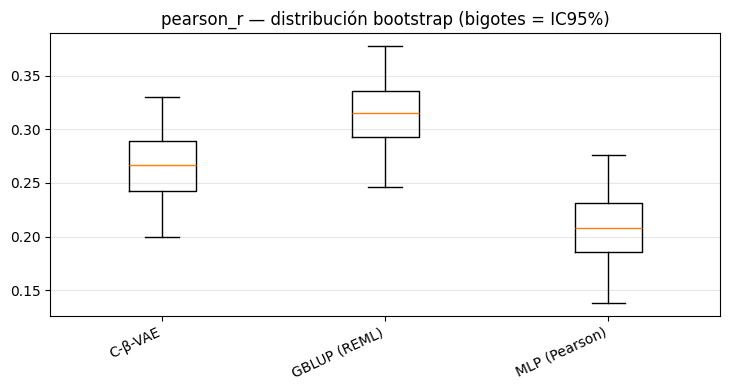

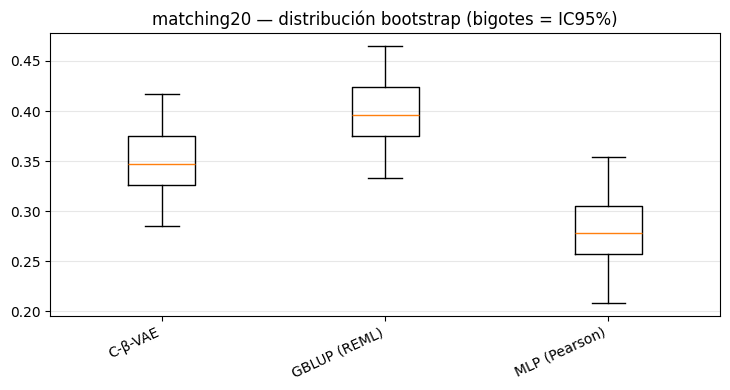

In [6]:
fig = plot_ci(df); plt.show()
for m in ("pearson_r", "matching20"):
    fig = plot_box(samples_by_model, m)
    if fig is not None:
        plt.show()

## 4 * Data augmentation

Reentrenamos un modelo downstream con el train real + los sintéticos de cada estrategia y lo comparamos
contra el mismo modelo entrenado solo con el train real, midiendo en val 2019 (100 % real). Las filas
sintéticas llevan `line_id` centinela que no cruza a val.

El downstream es configurable y puede venir de su propio sweep: poné `DOWNSTREAM_SWEEP` y se buscan los HP
del mejor modelo del sweep, que se reentrena con 2017+2018 + datos sintéticos y se testea en 2019.

- `DOWNSTREAM_CFG`: config base del modelo a reentrenar (debe matchear el `model.name` del sweep). Su `cv`/`data`
  no importan: el entrenamiento usa los arrays aumentados que arma el experimento.
- `DOWNSTREAM_SWEEP`: `"oromagnoli-/maze-genomic-pred/<sweep_id>"` del downstream (`None` => HP base del config).
- `DOWNSTREAM_RANK`: `1` = mejor del sweep, `2` = segundo, etc.

Ejemplos: MLP -> (`exp_mlp_2017_to_2018.yaml`, su `sweep_mlp`); el propio C-β-VAE -> (`exp_cbeta_vae_2017_to_2018.yaml`,
`sweep_cbeta_vae`); GBLUP -> (`exp_gblup_2017_to_2018.yaml`, sin sweep).

In [7]:
DOWNSTREAM_CFG   = "configs/exp_mlp_2017_to_2018.yaml"
DOWNSTREAM_SWEEP = "oromagnoli-/maze-genomic-pred/kyl04lf5"
DOWNSTREAM_RANK  = 1

downstream_builder = aug.downstream_from_sweep(
    DOWNSTREAM_CFG, sweep_id=DOWNSTREAM_SWEEP, rank=DOWNSTREAM_RANK,
)

res_aug = aug.evaluate_augmentation(
    vae_model=model,
    X_tr=Xtr, y_tr=ytr, line_id_tr=line_tr, year_tr=year_tr,
    X_va=Xva, y_va=ytrue, line_id_va=line_va,
    downstream_builder=downstream_builder,
    strategies=("posterior", "prior"),
    n_synth= len(Xtr),
    n_boot=2000, alpha=0.05, seed=575,
)

df_aug = pd.DataFrame(res_aug["rows"])
print(f"n_synth = {res_aug['n_synth']}")
print(df_aug.pivot(index="model", columns="metric", values="point").round(4))

[augment] downstream con HP del sweep oromagnoli-/maze-genomic-pred/kyl04lf5 (rank 1, 9 HP)
n_synth = 2319
metric                          matching20  pearson_r        r2     rmse
model                                                                   
+sintetico (posterior, n=2319)      0.3056     0.2564 -531.2809  23.2772
+sintetico (prior, n=2319)          0.3403     0.2871 -497.2497  22.5208
original (solo real)                0.3750     0.2618 -623.7099  25.2173


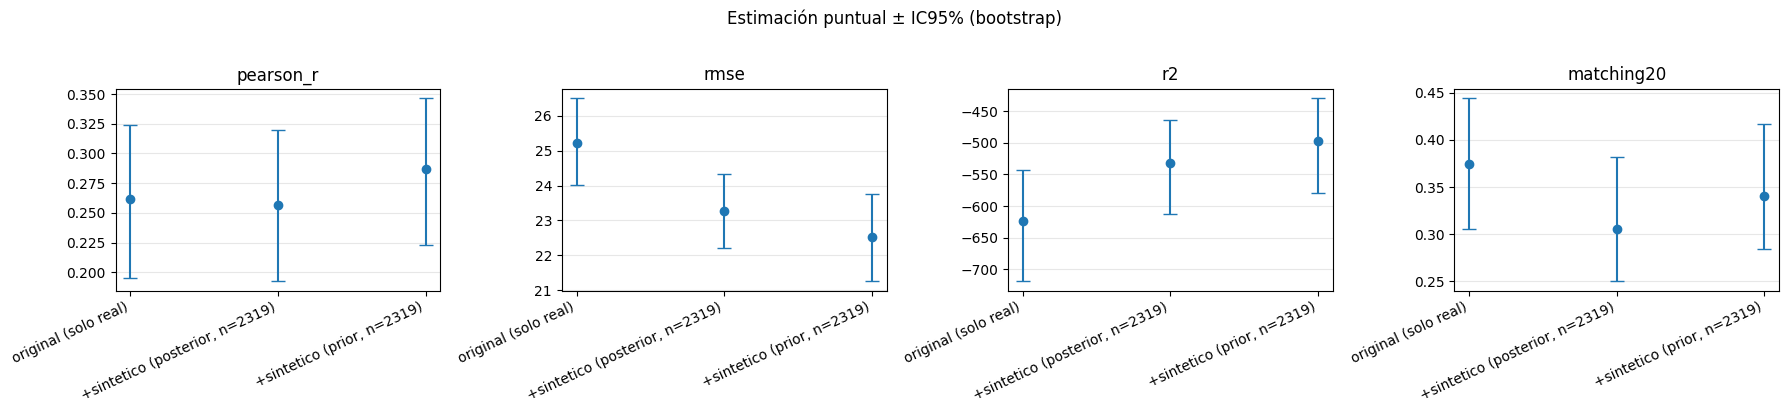

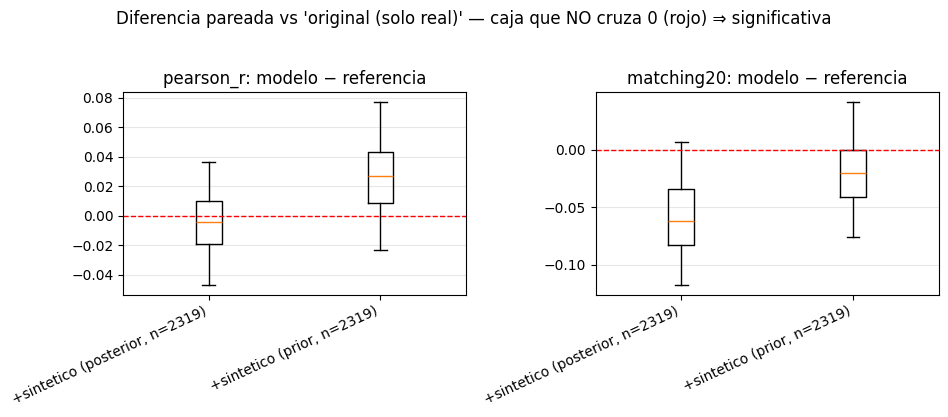

In [8]:
fig = plot_ci(df_aug); plt.show()

fig = plot_paired_diff(res_aug["samples_by_variant"], ref="original (solo real)",
                       metrics=["pearson_r", "matching20"])
plt.show()

Lectura: si la caja del test pareado (sección 4) no cruza el 0 en `pearson_r`/`matching20`, el augmentation
movió la métrica de forma significativa (signo + => ayuda). Comparar `posterior` (label real, suele ser más seguro)
vs `prior` (label auto-generado) indica de dónde viene —o no— la señal extra.